In [1]:
import json
import glob
import matplotlib.pyplot as plt
import numpy as np

from pathlib import Path

In [64]:
def get_ppo_log_files():
    base_dir = Path("../../../../results/methods/Hyperparams_controller/ppo_logs")
    return sorted(glob.glob(str(base_dir / "*.json")))

files = get_ppo_log_files()
print(f"Found {len(files)} JSON files: {files}")

Found 72 JSON files: ['..\\..\\..\\..\\results\\methods\\Hyperparams_controller\\ppo_logs\\C102_50_5.json', '..\\..\\..\\..\\results\\methods\\Hyperparams_controller\\ppo_logs\\C103_100_10.json', '..\\..\\..\\..\\results\\methods\\Hyperparams_controller\\ppo_logs\\C104_100_10.json', '..\\..\\..\\..\\results\\methods\\Hyperparams_controller\\ppo_logs\\C105_50_5.json', '..\\..\\..\\..\\results\\methods\\Hyperparams_controller\\ppo_logs\\C107_100_10.json', '..\\..\\..\\..\\results\\methods\\Hyperparams_controller\\ppo_logs\\C109_50_5.json', '..\\..\\..\\..\\results\\methods\\Hyperparams_controller\\ppo_logs\\C1_2_4_20.json', '..\\..\\..\\..\\results\\methods\\Hyperparams_controller\\ppo_logs\\C1_2_8_20.json', '..\\..\\..\\..\\results\\methods\\Hyperparams_controller\\ppo_logs\\C1_2_9_20.json', '..\\..\\..\\..\\results\\methods\\Hyperparams_controller\\ppo_logs\\C1_410_40.json', '..\\..\\..\\..\\results\\methods\\Hyperparams_controller\\ppo_logs\\C1_4_1_40.json', '..\\..\\..\\..\\results\\

In [61]:
for i, f in enumerate(files):
    print(i, Path(f).name)

0 C102_50_5.json
1 C103_100_10.json
2 C104_100_10.json
3 C105_50_5.json
4 C107_100_10.json
5 C109_50_5.json
6 C1_2_4_20.json
7 C1_2_8_20.json
8 C1_2_9_20.json
9 C1_410_40.json
10 C1_4_1_40.json
11 C1_4_5_40.json
12 C201_50_5.json
13 C202_100_10.json
14 C204_50_5.json
15 C206_100_10.json
16 C207_50_5.json
17 C208_100_10.json
18 C2_2_2_20.json
19 C2_2_5_20.json
20 C2_2_7_20.json
21 C2_4_2_40.json
22 C2_4_4_40.json
23 C2_4_8_40.json
24 R101_100_10.json
25 R102_50_5.json
26 R105_100_10.json
27 R106_50_5.json
28 R110_50_5.json
29 R111_100_10.json
30 R1_2_1_20.json
31 R1_2_3_20.json
32 R1_2_5_20.json
33 R1_4_3_40.json
34 R1_4_7_40.json
35 R1_4_9_40.json
36 R203_100_10.json
37 R203_50_5.json
38 R207_100_10.json
39 R209_50_5.json
40 R210_100_10.json
41 R211_50_5.json
42 R2_2_2_20.json
43 R2_2_4_20.json
44 R2_2_6_20.json
45 R2_4_1_40.json
46 R2_4_4_40.json
47 R2_4_6_40.json
48 RC101_100_10.json
49 RC103_50_5.json
50 RC104_100_10.json
51 RC104_50_5.json
52 RC106_100_10.json
53 RC108_50_5.json
54

In [65]:
selected_file = files[15]

# Action distribution

In [3]:
ACTION_NAMES = {
    0: "Neutral",
    1: "Strong div.",
    2: "Mild div.",
    3: "Mild intens.",
    4: "Strong intens.",
    5: "Strong feas.",
    6: "Mild feas.",
    7: "Reset"
}

def plot_action_distribution(log_path):

    with open(log_path, "r") as f:
        logs = json.load(f)

    actions = [x["action"] for x in logs]

    counts = np.bincount(actions, minlength=8)

    plt.figure(figsize=(10,4))

    plt.bar(range(8), counts)

    plt.xticks(
        range(8),
        [ACTION_NAMES[i] for i in range(8)],
        rotation=20
    )

    plt.ylabel("Frequency")
    plt.title("Distribution of PPO controller actions")

    plt.grid(axis='y', alpha=0.2)

    plt.tight_layout()
    plt.show()

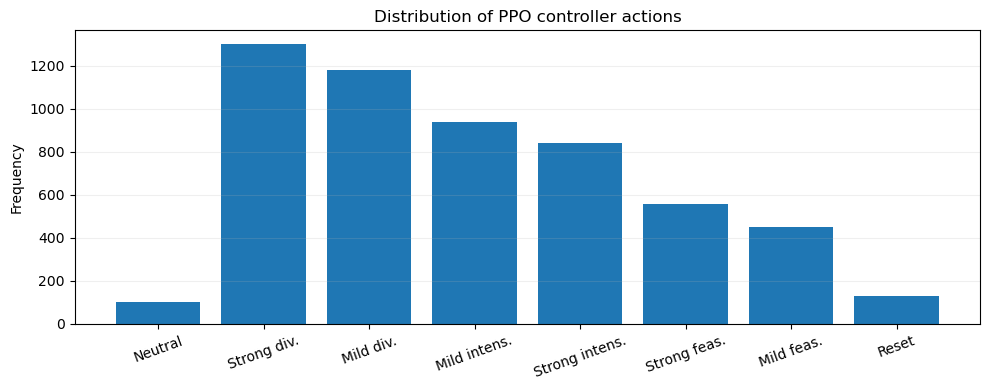

In [66]:
plot_action_distribution(selected_file)
# for log_path in files: 
#     print(f"Plotting actions over time for: {log_path}") 
#     plot_action_distribution(log_path)

# Action over time

In [76]:
def plot_actions_over_time(log_path, sample_rate=100):

    with open(log_path, "r") as f:
        logs = json.load(f)

    actions = [x["action"] for x in logs]
    
    # Sample every N iterations for clarity
    sampled_indices = list(range(0, len(actions), sample_rate))
    sampled_actions = [actions[i] for i in sampled_indices]

    plt.figure(figsize=(14,4))

    plt.step(
        sampled_indices,
        sampled_actions,
        where='post',
        linewidth=1.5,
        marker='o',
        markersize=4
    )

    plt.yticks(
        range(8),
        [ACTION_NAMES[i] for i in range(8)]
    )

    plt.xlabel(f"Search iteration (sampled every {sample_rate})")
    plt.ylabel("Selected action")

    plt.title(f"Evolution of PPO control actions during search (n={len(actions)} total, sampled every {sample_rate})")

    plt.grid(alpha=0.2)

    plt.tight_layout()
    plt.show()

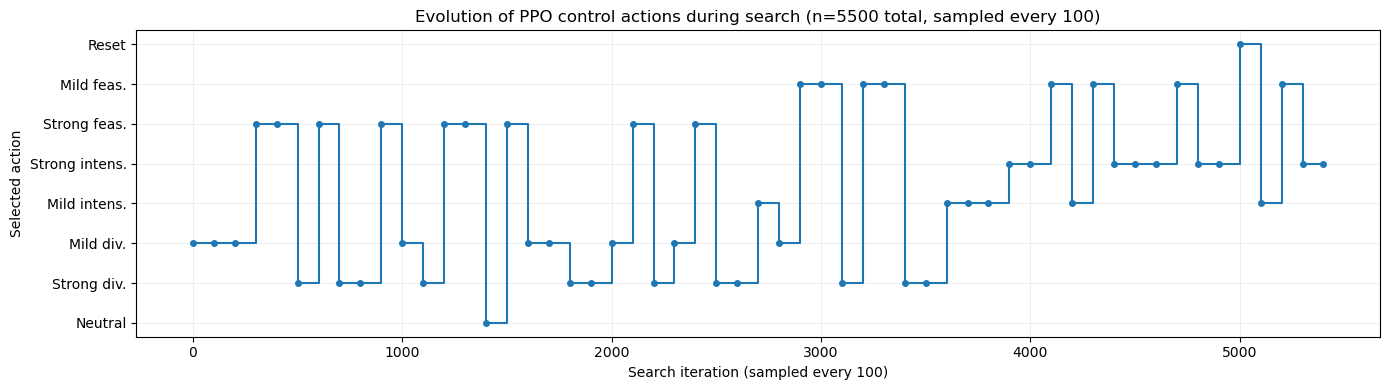

In [77]:
plot_actions_over_time(selected_file)